In [3]:
""" Corner Plot & Heatmap - IGNORE

Wired to: master_results.csv  (3069 galaxies, 42 columns)

Three plots, one config section (Section 3):

  PLOT 1 — Corner Plot
            Driver variables (log_Mstar, log_sSFR, log_5NN, log_MassA_1)
            with an SF metric colour-coded on every scatter cell.
            Run once per metric (G / C / A / S).

  PLOT 2 — Binned Heatmap Grid
            Rows = SF metrics.  Columns = environment bins.
            Each cell = median metric in log_Mstar × log_sSFR bins.
            Answers: "how does metric X change with mass / SFR / environment?"

  PLOT 3 — Violin / Distribution Plot
            Metric distributions split by environment category.
            One panel per metric — the clean statistical summary.

  SFMS    — Star-forming main sequence overlay drawn on any panel whose
            axes are log_Mstar (x) and log_SFR or log_sSFR (y).

================================================================================
DATA NOTES (master_results.csv)
  Internally used column names after cleaning:
      CATID, log_Mstar, log_SFR, log_sSFR,
      G, C, A, S,
      environment,          # "GAMA" | "Cluster"
      env3,                 # derived: "Isolated" | "Group/Field" | "Cluster"
      is_isolated,          # bool
      log_5NN,              # derived: log10(5NN)  — raw 5NN is not log-scaled
      log_MassA_1,          # BCG/halo mass proxy (1143 non-null)
      spectral_class        # "pure_SF" | "composite_SF"

  Sentinel / bad values cleaned on load:
      C  == -999   → NaN
      A  == inf    → NaN
================================================================================
STRUCTURE
  1. Imports & aesthetics
  2. Data loading & cleaning
  3. ══════════════════════════════════════════
     CONFIGURATION  ← only section to edit
  ══════════════════════════════════════════
  4. Data cuts (derived from config)
  5. SFMS helper
  6. Plot 1 — Corner plot
  7. Plot 2 — Heatmap grid
  8. Plot 3 — Violin plot
  9. Main execution
================================================================================
"""

# ── 1. IMPORTS & AESTHETICS ───────────────────────────────────────────────────

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import gaussian_kde

plt.rcParams.update({
    "figure.dpi":       150,
    "font.family":      "serif",
    "axes.labelsize":   11,
    "axes.titlesize":   11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "axes.grid":        True,
    "grid.alpha":       0.25,
    "grid.linestyle":   "--",
})


# ── 2. DATA LOADING & CLEANING ────────────────────────────────────────────────

def load_and_clean(filepath: str) -> pd.DataFrame:
    """
    Load master_results.csv, clean sentinels, and derive convenience columns.
    All downstream code uses the internal names listed in the module docstring.
    """
    df = pd.read_csv(filepath)

    # ── Sentinel / bad value removal ──────────────────────────────────────
    df.loc[df["C"] == -999, "C"] = np.nan          # one C sentinel
    df.loc[np.isinf(df["A"]),  "A"] = np.nan       # one A = inf

    # ── Derived columns ───────────────────────────────────────────────────
    # log-scale 5NN (raw values span 0.004 – 637; heavily skewed)
    df["log_5NN"] = np.log10(df["5NN"].clip(lower=1e-6))

    # Three-way environment label for richer stratification
    # GAMA + is_isolated=True  → "Isolated"
    # GAMA + is_isolated=False → "Group/Field"
    # Cluster                  → "Cluster"
    conditions = [
        (df["environment"] == "Cluster"),
        (df["environment"] == "GAMA") & (~df["is_isolated"]),
        (df["environment"] == "GAMA") & (df["is_isolated"]),
    ]
    choices = ["Cluster", "Group/Field", "Isolated"]
    df["env3"] = np.select(conditions, choices, default="Unknown")

    return df


# ── 3. CONFIGURATION ══════════════════════════════════════════════════════════
#
#   Edit ONLY this section between runs.
#   Everything below adapts automatically.
#
# ═════════════════════════════════════════════════════════════════════════════

# ── 3a. Data path ─────────────────────────────────────────────────────────────

DATA_PATH = "../outputs/tables/master_results.csv"


# ── 3b. Sample filter ─────────────────────────────────────────────────────────
#
#   SPECTRAL_CLASSES   Which spectral classes to keep.
#                      Options: "pure_SF" | "composite_SF" | both (None)
#
#   REQUIRE_ALL_METRICS  If True, keep only galaxies that have G, C, A, and S.
#                        If False, each plot uses whatever is available per metric.
#
#   SSFR_CUT           Hard lower cut on log_sSFR (removes passive galaxies).
#                      Set to None to keep the full sample.
#                      Suggestion: -12.0  (removes the retired/passive tail)

SPECTRAL_CLASSES    = None           # ← None | "pure_SF" | "composite_SF"
REQUIRE_ALL_METRICS = False          # ← True | False
SSFR_CUT            = None          # ← float | None   e.g. -12.0


# ── 3c. Environment stratification ────────────────────────────────────────────
#
#   ENV_COL    Which environment column to use for grouping.
#              "environment"  →  2 bins: GAMA, Cluster
#              "env3"         →  3 bins: Isolated, Group/Field, Cluster
#              "is_isolated"  →  2 bins: True, False  (boolean cast to str)
#
#   ENV_ORDER  Display order of the bins (left → right in Plot 2, Plot 3).
#              Must match actual values in ENV_COL. Set to None to auto-detect.
#
#   ENV_COLORS One hex colour per bin in ENV_ORDER (used in Plot 3 violins).

ENV_COL    = "env3"
ENV_ORDER  = ["Isolated", "Group/Field", "Cluster"]   # ← None to auto
ENV_COLORS = ["#4C9BE8",  "#F5A623",     "#E84C4C"]


# ── 3d. SF metrics ────────────────────────────────────────────────────────────
#
#   These become the rows in Plot 2 and panels in Plot 3.
#   Comment out rows you don't want, or reorder freely.

METRICS = [
    {"col": "G", "label": "Gini (G)"},
    {"col": "C", "label": "Concentration (C)"},
    {"col": "A", "label": "Asymmetry (A)"},
    {"col": "S", "label": "Smoothness (S)"},
]


# ── 3e. Corner plot settings (Plot 1) ─────────────────────────────────────────
#
#   CORNER_DRIVERS   Variables on the corner plot axes.
#                    Must be numeric columns present after cleaning.
#
#   CORNER_METRIC    Which SF metric colours the scatter points.
#                    Must match a "col" value in METRICS.
#
#   CORNER_CMAP      Any matplotlib colourmap.

CORNER_DRIVERS = [
    {"col": "log_Mstar",   "label": r"$\log\,M_\star$"},
    {"col": "log_sSFR",    "label": r"$\log\,\mathrm{sSFR}$"},
    {"col": "log_5NN",     "label": r"$\log\,\Sigma_\mathrm{5NN}$"},
    {"col": "log_MassA_1", "label": r"$\log\,M_\mathrm{halo}$"},
]

CORNER_METRIC = "G"                  # ← "G" | "C" | "A" | "S"
CORNER_CMAP   = "plasma"


# ── 3f. Heatmap grid settings (Plot 2) ────────────────────────────────────────
#
#   HEATMAP_X / Y    Axes of every heatmap cell.
#                    Default: M★ vs sSFR (your foundational plot).
#
#   N_BINS_X / Y     Number of equal-width bins per axis.
#
#   HEATMAP_STAT     Cell statistic: "median" | "mean" | "std"
#                    Tip: switch to "std" to see where metric *variance* peaks.
#
#   HEATMAP_MIN_N    Bins with fewer galaxies than this are masked grey.

HEATMAP_X    = {"col": "log_Mstar", "label": r"$\log\,M_\star$"}
HEATMAP_Y    = {"col": "log_sSFR",  "label": r"$\log\,\mathrm{sSFR}$"}
N_BINS_X     = 8
N_BINS_Y     = 8
HEATMAP_STAT = "median"              # ← "median" | "mean" | "std"
HEATMAP_MIN_N = 5


# ── 3g. Star-forming main sequence (SFMS) ─────────────────────────────────────
#
#   The SFMS is drawn on any panel whose x-axis is log_Mstar AND whose
#   y-axis is log_SFR or log_sSFR.
#
#   SFMS_SHOW      Master toggle. False suppresses SFMS on all plots.
#
#   SFMS_SOURCE    How to define the SFMS:
#       "fit"      — fit a line to the star-forming galaxies in your sample
#                    (log_sSFR > SFMS_FIT_SSFR_FLOOR).  Robust and self-consistent.
#       "renzini"  — Renzini & Peng (2015) parametrisation:
#                    log(SFR) = 0.76 * log(M★) − 7.64
#       "speagle"  — Speagle et al. (2014) at z = 0.08 (median z of SAMI):
#                    log(SFR) = (0.84 − 0.026*t) * log(M★) − (6.51 − 0.11*t)
#                    where t = age of universe at z=0.08 ≈ 12.4 Gyr
#       "manual"   — supply SFMS_SLOPE and SFMS_INTERCEPT directly
#                    (in log_SFR = slope * log_Mstar + intercept space)
#
#   SFMS_SCATTER   ±N-sigma shaded band around the SFMS line (0 = no band).
#
#   SFMS_FIT_SSFR_FLOOR   log_sSFR floor used when SFMS_SOURCE = "fit" to
#                          exclude passive galaxies from the fit.

SFMS_SHOW            = True
SFMS_SOURCE          = "fit"         # ← "fit" | "renzini" | "speagle" | "manual"
SFMS_SCATTER         = 1.0           # ← sigma bands (0 to suppress)
SFMS_FIT_SSFR_FLOOR  = -12.0        # ← used only when SFMS_SOURCE = "fit"
SFMS_SLOPE           = 0.675        # ← used only when SFMS_SOURCE = "manual"
SFMS_INTERCEPT       = -7.268       # ← used only when SFMS_SOURCE = "manual"


# ── 3h. Output ────────────────────────────────────────────────────────────────

SAVE_FIGURES = True
OUTPUT_DIR   = "."                   # ← folder for saved figures
FIG_FORMAT   = "pdf"                 # ← "pdf" | "png" | "svg"
SHOW_FIGURES = True

# ══ END OF CONFIGURATION ══════════════════════════════════════════════════════


# ── 4. DATA CUTS ──────────────────────────────────────────────────────────────

def prepare_data(filepath: str) -> pd.DataFrame:
    """Load, clean, and apply all sample filters from Section 3."""

    print(f"\nLoading: {filepath}")
    df = load_and_clean(filepath)
    print(f"  Raw catalogue  : {len(df):,} galaxies, {df.shape[1]} columns")

    # Spectral class filter
    if SPECTRAL_CLASSES is not None:
        targets = ([SPECTRAL_CLASSES]
                   if isinstance(SPECTRAL_CLASSES, str)
                   else list(SPECTRAL_CLASSES))
        df = df[df["spectral_class"].isin(targets)]
        print(f"  Spectral class {targets}: → {len(df):,}")

    # sSFR hard cut
    if SSFR_CUT is not None and "log_sSFR" in df.columns:
        df = df[df["log_sSFR"].isna() | (df["log_sSFR"] >= SSFR_CUT)]
        print(f"  log_sSFR ≥ {SSFR_CUT}: → {len(df):,}")

    # Require all four metrics simultaneously
    if REQUIRE_ALL_METRICS:
        metric_cols = [m["col"] for m in METRICS]
        df = df.dropna(subset=metric_cols)
        print(f"  Require all metrics ({metric_cols}): → {len(df):,}")

    # Surface Density 
    if "SurfaceDensityFlag" in df.columns:
        df = df[df["SurfaceDensityFlag"] <= 1]

    # Warn if ENV_COL has unexpected NaNs
    n_env_null = df[ENV_COL].isna().sum() if ENV_COL in df.columns else 0
    if n_env_null > 0:
        print(f"  ⚠  {n_env_null} galaxies have NaN in '{ENV_COL}' — excluded from env-split plots")

    print(f"  Final sample   : {len(df):,} galaxies\n")
    return df


def get_env_bins(df: pd.DataFrame) -> list:
    """Return the ordered list of environment bin labels to use."""
    if ENV_ORDER is not None:
        return ENV_ORDER
    return sorted(df[ENV_COL].dropna().unique().tolist())


# ── 5. SFMS HELPER ────────────────────────────────────────────────────────────

def compute_sfms(df: pd.DataFrame) -> dict:
    """
    Return a dict with keys:
        slope, intercept   — log_SFR = slope * log_Mstar + intercept
        sigma              — 1-sigma scatter of SF galaxies around the line
        label              — legend string
    Uses SFMS_SOURCE to select the parametrisation.
    """
    if SFMS_SOURCE == "renzini":
        slope, intercept = 0.76, -7.64
        label = "SFMS (Renzini & Peng 2015)"

    elif SFMS_SOURCE == "speagle":
        t = 12.4          # Gyr — age of universe at z ≈ 0.08
        slope     = 0.84 - 0.026 * t
        intercept = -(6.51 - 0.11 * t)
        label = "SFMS (Speagle+2014, z=0.08)"

    elif SFMS_SOURCE == "manual":
        slope, intercept = SFMS_SLOPE, SFMS_INTERCEPT
        label = f"SFMS (manual: {slope:.2f}·M★ + {intercept:.2f})"

    else:  # "fit" — default
        sf = df[
            df["log_SFR"].notna() &
            df["log_Mstar"].notna() &
            (df["log_sSFR"] >= SFMS_FIT_SSFR_FLOOR)
        ]
        if len(sf) < 20:
            print("  ⚠  Too few SF galaxies for SFMS fit — falling back to Renzini & Peng")
            return compute_sfms_override("renzini", df)
        coeffs = np.polyfit(sf["log_Mstar"], sf["log_SFR"], 1)
        slope, intercept = coeffs[0], coeffs[1]
        label = f"SFMS (sample fit, N={len(sf):,})"

    # Compute scatter around the line using SF galaxies
    sf_all = df[df["log_SFR"].notna() & df["log_Mstar"].notna()]
    if SFMS_SOURCE in ("fit",):
        sf_all = sf_all[sf_all["log_sSFR"] >= SFMS_FIT_SSFR_FLOOR]
    residuals = sf_all["log_SFR"] - (slope * sf_all["log_Mstar"] + intercept)
    sigma = residuals.std() if len(residuals) > 5 else 0.3

    return {"slope": slope, "intercept": intercept, "sigma": sigma, "label": label}


def compute_sfms_override(source, df):
    """Internal fallback — temporarily overrides SFMS_SOURCE."""
    global SFMS_SOURCE
    orig = SFMS_SOURCE
    SFMS_SOURCE = source
    result = compute_sfms(df)
    SFMS_SOURCE = orig
    return result


def draw_sfms(ax, sfms: dict, x_col: str, y_col: str,
              mass_range: tuple = (7.0, 12.5)) -> None:
    """
    Draw the SFMS line (and optional scatter band) onto ax.
    Handles both log_SFR and log_sSFR y-axes automatically.
    Only draws if x_col == "log_Mstar" and y_col is SFR-related.
    """
    if not SFMS_SHOW:
        return
    if x_col != "log_Mstar":
        return
    if y_col not in ("log_SFR", "log_sSFR"):
        return

    xline = np.linspace(mass_range[0], mass_range[1], 200)
    yline_sfr = sfms["slope"] * xline + sfms["intercept"]

    if y_col == "log_sSFR":
        yline = yline_sfr - xline        # log_sSFR = log_SFR − log_Mstar
    else:
        yline = yline_sfr

    ax.plot(xline, yline, color="black", lw=1.5, ls="-",
            label=sfms["label"], zorder=6)

    if SFMS_SCATTER > 0:
        sigma = sfms["sigma"]
        ax.fill_between(
            xline,
            yline - SFMS_SCATTER * sigma,
            yline + SFMS_SCATTER * sigma,
            color="black", alpha=0.10, zorder=5,
            label=f"±{SFMS_SCATTER:.0f}σ = ±{sigma:.2f} dex",
        )


# ── 6. PLOT 1 — CORNER PLOT ───────────────────────────────────────────────────

def _pct_norm(series: pd.Series, cmap_name: str):
    vmin = series.quantile(0.02)
    vmax = series.quantile(0.98)
    return Normalize(vmin=vmin, vmax=vmax), plt.get_cmap(cmap_name)


def plot_corner(df: pd.DataFrame, sfms: dict) -> plt.Figure:
    """
    Plot 1 — Corner plot.
    Lower triangle : scatter coloured by CORNER_METRIC.
    Diagonal       : KDE of each driver variable.
    Upper triangle : empty.
    SFMS drawn on any cell with log_Mstar (x) vs log_SFR / log_sSFR (y).
    """
    drivers = CORNER_DRIVERS
    n       = len(drivers)
    metric  = CORNER_METRIC
    metric_label = next((m["label"] for m in METRICS if m["col"] == metric), metric)

    # Work only with rows that have the metric available
    plot_df = df.dropna(subset=[metric])
    norm, cmap = _pct_norm(plot_df[metric], CORNER_CMAP)

    fig, axes = plt.subplots(n, n, figsize=(2.8 * n, 2.8 * n), sharex="col")
    fig.subplots_adjust(hspace=0.05, wspace=0.05)

    for row in range(n):
        for col in range(n):
            ax = axes[row, col]

            # Upper triangle — hide
            if col > row:
                ax.set_visible(False)
                continue

            x_col = drivers[col]["col"]
            y_col = drivers[row]["col"]

            # Diagonal — KDE
            if col == row:
                vals = plot_df[x_col].dropna().values
                if len(vals) > 5:
                    kde = gaussian_kde(vals, bw_method="scott")
                    xs  = np.linspace(vals.min(), vals.max(), 300)
                    ax.plot(xs, kde(xs), color="#333333", lw=1.5)
                    ax.fill_between(xs, kde(xs), alpha=0.15, color="#333333")
                ax.set_yticks([])
                ax.grid(False)

            # Lower triangle — scatter
            else:
                sub = plot_df[[x_col, y_col, metric]].dropna()
                ax.scatter(
                    sub[x_col], sub[y_col],
                    c=sub[metric], cmap=cmap, norm=norm,
                    s=8, alpha=0.55, linewidths=0, rasterized=True,
                )
                draw_sfms(ax, sfms, x_col, y_col,
                          mass_range=(df["log_Mstar"].quantile(0.01),
                                      df["log_Mstar"].quantile(0.99)))
                # Legend only on the first cell that has the SFMS
                if x_col == "log_Mstar" and y_col in ("log_SFR", "log_sSFR"):
                    ax.legend(fontsize=6, loc="upper left")

            # Axis labels — outer edges only
            if row == n - 1:
                ax.set_xlabel(drivers[col]["label"], fontsize=9)
            else:
                ax.tick_params(labelbottom=False)

            if col == 0 and row != 0:
                ax.set_ylabel(drivers[row]["label"], fontsize=9)
            else:
                ax.tick_params(labelleft=False)

    # Shared colourbar
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.6])
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap),
                 cax=cbar_ax, label=metric_label)

    fig.suptitle(
        f"Corner plot — colour: {metric_label}  |  N = {len(plot_df):,}",
        y=1.01, fontsize=11,
    )
    return fig


# ── 7. PLOT 2 — BINNED HEATMAP GRID ──────────────────────────────────────────

def _bin_stat(df, xcol, ycol, metric_col, xbins, ybins, stat):
    nx, ny = len(xbins) - 1, len(ybins) - 1
    stat_g  = np.full((ny, nx), np.nan)
    count_g = np.zeros((ny, nx), dtype=int)
    sub = df[[xcol, ycol, metric_col]].dropna()
    xi = np.digitize(sub[xcol], xbins) - 1
    yi = np.digitize(sub[ycol], ybins) - 1
    for i in range(nx):
        for j in range(ny):
            mask = (xi == i) & (yi == j)
            vals = sub.loc[mask, metric_col]
            count_g[j, i] = len(vals)
            if len(vals) >= HEATMAP_MIN_N:
                stat_g[j, i] = (
                    np.median(vals) if stat == "median"
                    else np.mean(vals) if stat == "mean"
                    else np.std(vals)
                )
    return stat_g, count_g


def plot_heatmap_grid(df: pd.DataFrame, sfms: dict) -> plt.Figure:
    """
    Plot 2 — Heatmap grid.
    Rows = SF metrics.  Columns = environment bins.
    SFMS drawn on each cell where applicable.
    """
    env_bins  = get_env_bins(df)
    n_metrics = len(METRICS)
    n_envs    = len(env_bins)

    # Global bin edges (consistent across all cells)
    xbins = np.linspace(
        df[HEATMAP_X["col"]].quantile(0.01),
        df[HEATMAP_X["col"]].quantile(0.99),
        N_BINS_X + 1,
    )
    ybins = np.linspace(
        df[HEATMAP_Y["col"]].quantile(0.01),
        df[HEATMAP_Y["col"]].quantile(0.99),
        N_BINS_Y + 1,
    )

    fig, axes = plt.subplots(
        n_metrics, n_envs,
        figsize=(3.2 * n_envs, 3.0 * n_metrics),
        sharex=True, sharey=True,
    )
    if n_metrics == 1: axes = axes[np.newaxis, :]
    if n_envs    == 1: axes = axes[:, np.newaxis]
    fig.subplots_adjust(hspace=0.08, wspace=0.06)

    for r, metric in enumerate(METRICS):
        mcol, mlabel = metric["col"], metric["label"]
        all_vals = df[mcol].dropna()
        vmin, vmax = all_vals.quantile(0.05), all_vals.quantile(0.95)
        norm = Normalize(vmin=vmin, vmax=vmax)
        cmap = plt.get_cmap("viridis")

        for c, env in enumerate(env_bins):
            ax  = axes[r, c]
            sub = df[df[ENV_COL] == env]

            stat_grid, count_grid = _bin_stat(
                sub,
                HEATMAP_X["col"], HEATMAP_Y["col"],
                mcol, xbins, ybins, HEATMAP_STAT,
            )

            ax.pcolormesh(xbins, ybins, stat_grid,
                          cmap=cmap, norm=norm, shading="flat")

            # Grey mask for low-N bins
            masked = np.ma.masked_where(
                count_grid >= HEATMAP_MIN_N, np.ones_like(count_grid))
            ax.pcolormesh(xbins, ybins, masked,
                          cmap="Greys", vmin=0, vmax=1,
                          shading="flat", alpha=0.6)

            # SFMS overlay
            draw_sfms(ax, sfms,
                      HEATMAP_X["col"], HEATMAP_Y["col"],
                      mass_range=(xbins[0], xbins[-1]))

            if r == 0:
                ax.set_title(str(env), fontsize=10)
            if c == 0:
                ax.set_ylabel(f"{mlabel}\n{HEATMAP_Y['label']}", fontsize=9)
            else:
                ax.tick_params(labelleft=False)
            if r == n_metrics - 1:
                ax.set_xlabel(HEATMAP_X["label"], fontsize=9)
            else:
                ax.tick_params(labelbottom=False)

        # Per-row colourbar
        pos = axes[r, -1].get_position()
        cbar_ax = fig.add_axes([0.92, pos.y0, 0.012, pos.height])
        fig.colorbar(ScalarMappable(norm=norm, cmap=cmap),
                     cax=cbar_ax, label=f"{mlabel}\n({HEATMAP_STAT})")

    # Global SFMS legend — grab from the first applicable cell
    for r in range(n_metrics):
        ax0 = axes[r, 0]
        handles, labels = ax0.get_legend_handles_labels()
        if handles:
            fig.legend(handles, labels,
                       loc="upper right", bbox_to_anchor=(0.91, 1.0),
                       fontsize=8, framealpha=0.8)
            break

    fig.suptitle(
        f"Heatmap grid — {HEATMAP_STAT} metric in "
        f"{HEATMAP_X['label']} × {HEATMAP_Y['label']} bins  "
        f"| env: {ENV_COL}",
        y=1.02, fontsize=11,
    )
    return fig


# ── 8. PLOT 3 — VIOLIN / DISTRIBUTION PLOT ────────────────────────────────────

def plot_violin(df: pd.DataFrame) -> plt.Figure:
    """
    Plot 3 — Violin plot.
    One panel per SF metric.  X-axis = environment bins.
    Median = white dot; IQR = white bar.
    """
    env_bins = get_env_bins(df)
    palette  = dict(zip(env_bins, ENV_COLORS))

    n_metrics = len(METRICS)
    fig, axes = plt.subplots(1, n_metrics, figsize=(3.5 * n_metrics, 5),
                              sharey=False)
    if n_metrics == 1:
        axes = [axes]
    fig.subplots_adjust(wspace=0.35)

    for ax, metric in zip(axes, METRICS):
        mcol, mlabel = metric["col"], metric["label"]

        groups, labels, colors = [], [], []
        for env in env_bins:
            sub = df.loc[df[ENV_COL] == env, mcol].dropna()
            if len(sub) < 5:
                continue
            groups.append(sub.values)
            labels.append(str(env))
            colors.append(palette.get(env, "#888888"))

        if not groups:
            ax.set_title(mlabel)
            ax.text(0.5, 0.5, "No data", ha="center", va="center",
                    transform=ax.transAxes)
            continue

        positions = np.arange(1, len(groups) + 1)
        parts = ax.violinplot(groups, positions=positions,
                              showmedians=False, showextrema=False, widths=0.65)
        for body, col in zip(parts["bodies"], colors):
            body.set_facecolor(col)
            body.set_edgecolor("white")
            body.set_alpha(0.82)

        # Median + IQR markers
        for pos, vals, col in zip(positions, groups, colors):
            q25, med, q75 = np.percentile(vals, [25, 50, 75])
            ax.vlines(pos, q25, q75, color="white", lw=3, zorder=4)
            ax.scatter(pos, med, color="white", s=28, zorder=5)

        ax.set_xticks(positions)
        ax.set_xticklabels(labels, fontsize=9)
        ax.set_ylabel(mlabel, fontsize=10)
        ax.set_title(mlabel, fontsize=10)
        ax.grid(axis="y", alpha=0.3, ls="--")
        ax.grid(axis="x", visible=False)

        # Sample sizes as text
        for pos, grp, lbl in zip(positions, groups, labels):
            ax.text(pos, ax.get_ylim()[0] if ax.get_ylim()[0] > -999 else 0,
                    f"n={len(grp)}", ha="center", va="bottom",
                    fontsize=7, color="#555555")

    fig.suptitle(
        f"Metric distributions by environment ({ENV_COL})  |  N = {len(df):,}",
        y=1.02, fontsize=11,
    )
    return fig


# ── 9. MAIN EXECUTION ─────────────────────────────────────────────────────────

def save(fig: plt.Figure, name: str) -> None:
    if SAVE_FIGURES:
        path = f"{OUTPUT_DIR}/{name}.{FIG_FORMAT}"
        fig.savefig(path, bbox_inches="tight")
        print(f"  Saved → {path}")


def main():
    print("=" * 64)
    print("SAMI Galaxy Survey — Multi-Plot Analysis Scaffold")
    print("=" * 64)

    df = prepare_data(DATA_PATH)

    # Compute SFMS once — shared across all plots
    print("Computing SFMS …")
    sfms = compute_sfms(df)
    print(f"  {sfms['label']}")
    print(f"  log_SFR = {sfms['slope']:.3f} · log_Mstar + {sfms['intercept']:.3f}")
    print(f"  1σ scatter = {sfms['sigma']:.3f} dex\n")

    # ── Plot 1: Corner plot ───────────────────────────────────────────────
    print("Plot 1: Corner plot …")
    fig1 = plot_corner(df, sfms)
    save(fig1, "plot1_corner")
    if SHOW_FIGURES:
        plt.show()

    # ── Plot 2: Heatmap grid ──────────────────────────────────────────────
    print("Plot 2: Heatmap grid …")
    fig2 = plot_heatmap_grid(df, sfms)
    save(fig2, "plot2_heatmap_grid")
    if SHOW_FIGURES:
        plt.show()

    # ── Plot 3: Violin plot ───────────────────────────────────────────────
    print("Plot 3: Violin plot …")
    # fig3 = plot_violin(df)
    # save(fig3, "plot3_violin")
    # if SHOW_FIGURES:
    #     plt.show()

    print("\nDone.")


if __name__ == "__main__":
    main()

SAMI Galaxy Survey — Multi-Plot Analysis Scaffold

Loading: ../outputs/tables/master_results.csv


TypeError: bad operand type for unary ~: 'str'

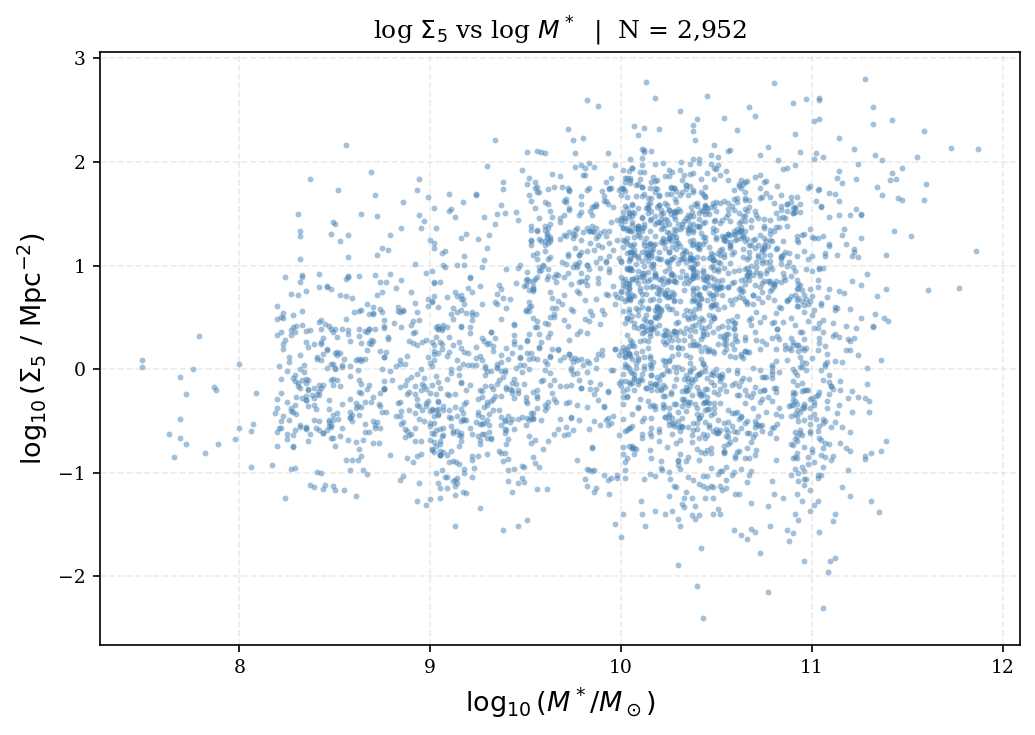

In [ ]:
""" M* vs Fifth Nearest Neighbour (Full Sample)"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_check = pd.read_csv("../outputs/tables/master_results.csv")

# Apply quality flag if present
if "SurfaceDensityFlag" in df_check.columns:
    df_check = df_check[df_check["SurfaceDensityFlag"] <= 1]
    print(f"After flag cut: {len(df_check):,} galaxies")

df_check["log_5NN"] = np.log10(df_check["5NN"].clip(lower=1e-6))

plot = df_check[["log_Mstar", "log_5NN"]].dropna()

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    plot["log_Mstar"], plot["log_5NN"],
    s=8, alpha=0.5, linewidths=0, color="steelblue"
)

ax.set_xlabel(r"$\log_{10}(M^*/M_\odot)$", fontsize=13)
ax.set_ylabel(r"$\log_{10}(\Sigma_5\ /\ \mathrm{Mpc}^{-2})$", fontsize=13)
ax.set_title(f"log $\\Sigma_5$ vs log $M^*$  |  N = {len(plot):,}", fontsize=12)

plt.tight_layout()
plt.show()

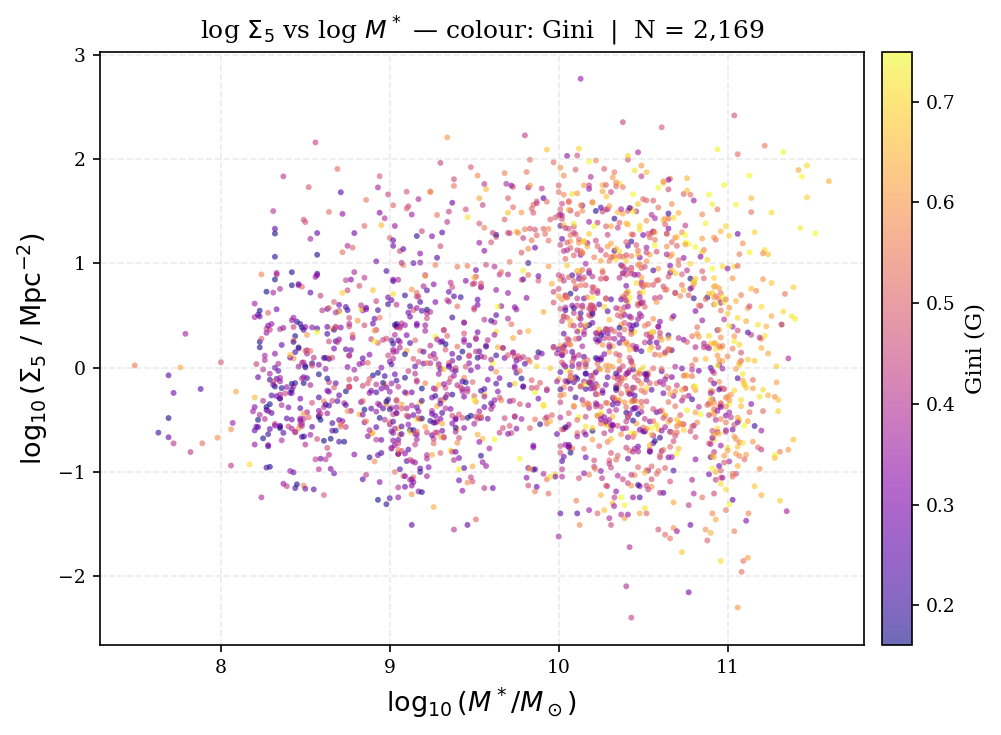

In [ ]:
""" M* vs Fifth Nearest Neighbour (Coloured by Gini)"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_check = pd.read_csv("../outputs/tables/master_results.csv")

# Apply quality flag if present
if "SurfaceDensityFlag" in df_check.columns:
    df_check = df_check[df_check["SurfaceDensityFlag"] <= 1]
    print(f"After flag cut: {len(df_check):,} galaxies")

df_check["log_5NN"] = np.log10(df_check["5NN"].clip(lower=1e-6))

plot = df_check[["log_Mstar", "log_5NN", "G"]].dropna()  # ← added "G"

fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    plot["log_Mstar"], plot["log_5NN"],
    c=plot["G"],
    cmap="plasma",
    vmin=plot["G"].quantile(0.02),
    vmax=plot["G"].quantile(0.98),
    s=8, alpha=0.6, linewidths=0,
)

fig.colorbar(sc, ax=ax, label="Gini (G)", pad=0.02)

ax.set_xlabel(r"$\log_{10}(M^*/M_\odot)$", fontsize=13)
ax.set_ylabel(r"$\log_{10}(\Sigma_5\ /\ \mathrm{Mpc}^{-2})$", fontsize=13)
ax.set_title(f"log $\\Sigma_5$ vs log $M^*$ — colour: Gini  |  N = {len(plot):,}", fontsize=12)

plt.tight_layout()
plt.show()

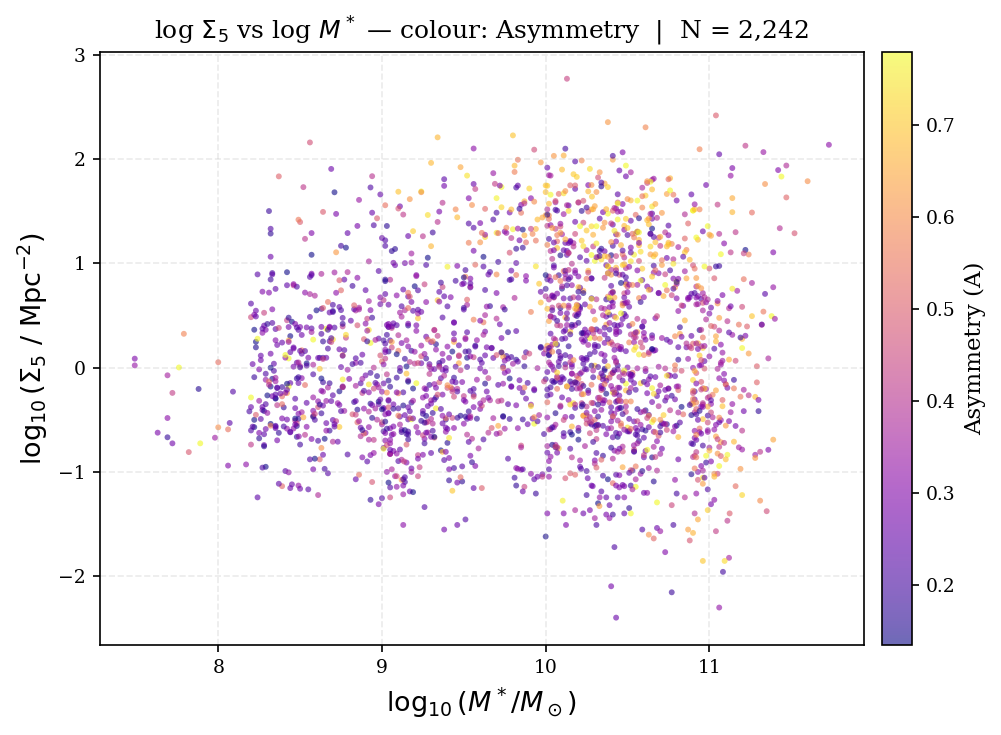

In [ ]:
""" M* vs Fifth Nearest Neighbour (Coloured by Asymmetry)"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_check = pd.read_csv("../outputs/tables/master_results.csv")

# Apply quality flag if present
if "SurfaceDensityFlag" in df_check.columns:
    df_check = df_check[df_check["SurfaceDensityFlag"] <= 1]
    print(f"After flag cut: {len(df_check):,} galaxies")

df_check["log_5NN"] = np.log10(df_check["5NN"].clip(lower=1e-6))

plot = df_check[["log_Mstar", "log_5NN", "A"]].dropna()  # ← added "G"

fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    plot["log_Mstar"], plot["log_5NN"],
    c=plot["A"],
    cmap="plasma",
    vmin=plot["A"].quantile(0.02),
    vmax=plot["A"].quantile(0.98),
    s=8, alpha=0.6, linewidths=0,
)

fig.colorbar(sc, ax=ax, label="Asymmetry (A)", pad=0.02)

ax.set_xlabel(r"$\log_{10}(M^*/M_\odot)$", fontsize=13)
ax.set_ylabel(r"$\log_{10}(\Sigma_5\ /\ \mathrm{Mpc}^{-2})$", fontsize=13)
ax.set_title(f"log $\\Sigma_5$ vs log $M^*$ — colour: Asymmetry  |  N = {len(plot):,}", fontsize=12)

plt.tight_layout()
plt.show()

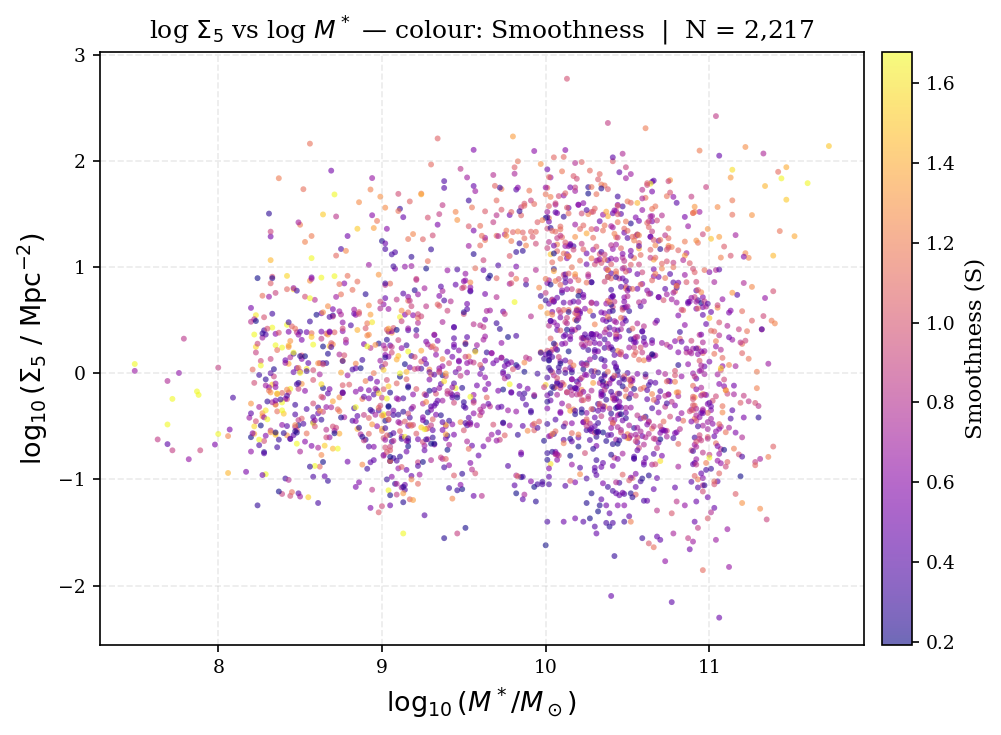

In [ ]:
""" M* vs Fifth Nearest Neighbour (Coloured by Smoothness)"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_check = pd.read_csv("../outputs/tables/master_results.csv")

# Apply quality flag if present
if "SurfaceDensityFlag" in df_check.columns:
    df_check = df_check[df_check["SurfaceDensityFlag"] <= 1]
    print(f"After flag cut: {len(df_check):,} galaxies")

df_check["log_5NN"] = np.log10(df_check["5NN"].clip(lower=1e-6))

plot = df_check[["log_Mstar", "log_5NN", "S"]].dropna()  # ← added "G"

fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    plot["log_Mstar"], plot["log_5NN"],
    c=plot["S"],
    cmap="plasma",
    vmin=plot["S"].quantile(0.02),
    vmax=plot["S"].quantile(0.98),
    s=8, alpha=0.6, linewidths=0,
)

fig.colorbar(sc, ax=ax, label="Smoothness (S)", pad=0.02)

ax.set_xlabel(r"$\log_{10}(M^*/M_\odot)$", fontsize=13)
ax.set_ylabel(r"$\log_{10}(\Sigma_5\ /\ \mathrm{Mpc}^{-2})$", fontsize=13)
ax.set_title(f"log $\\Sigma_5$ vs log $M^*$ — colour: Smoothness  |  N = {len(plot):,}", fontsize=12)

plt.tight_layout()
plt.show()

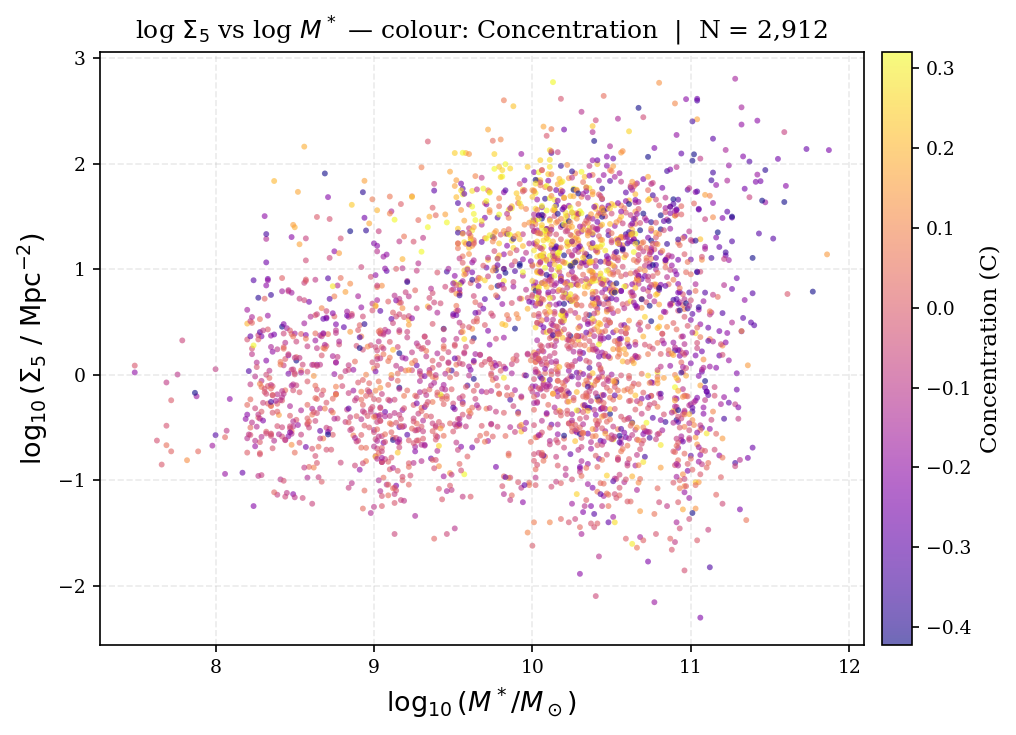

In [ ]:
""" M* vs Fifth Nearest Neighbour (Coloured by Concentration)"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_check = pd.read_csv("../outputs/tables/master_results.csv")

# Apply quality flag if present
if "SurfaceDensityFlag" in df_check.columns:
    df_check = df_check[df_check["SurfaceDensityFlag"] <= 1]
    print(f"After flag cut: {len(df_check):,} galaxies")

df_check["log_5NN"] = np.log10(df_check["5NN"].clip(lower=1e-6))

plot = df_check[["log_Mstar", "log_5NN", "C"]].dropna()  # ← added "G"

fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    plot["log_Mstar"], plot["log_5NN"],
    c=plot["C"],
    cmap="plasma",
    vmin=plot["C"].quantile(0.02),
    vmax=plot["C"].quantile(0.98),
    s=8, alpha=0.6, linewidths=0,
)

fig.colorbar(sc, ax=ax, label="Concentration (C)", pad=0.02)

ax.set_xlabel(r"$\log_{10}(M^*/M_\odot)$", fontsize=13)
ax.set_ylabel(r"$\log_{10}(\Sigma_5\ /\ \mathrm{Mpc}^{-2})$", fontsize=13)
ax.set_title(f"log $\\Sigma_5$ vs log $M^*$ — colour: Concentration  |  N = {len(plot):,}", fontsize=12)

plt.tight_layout()
plt.show()

Galaxies with both log_sSFR and log_MassA_1: 932


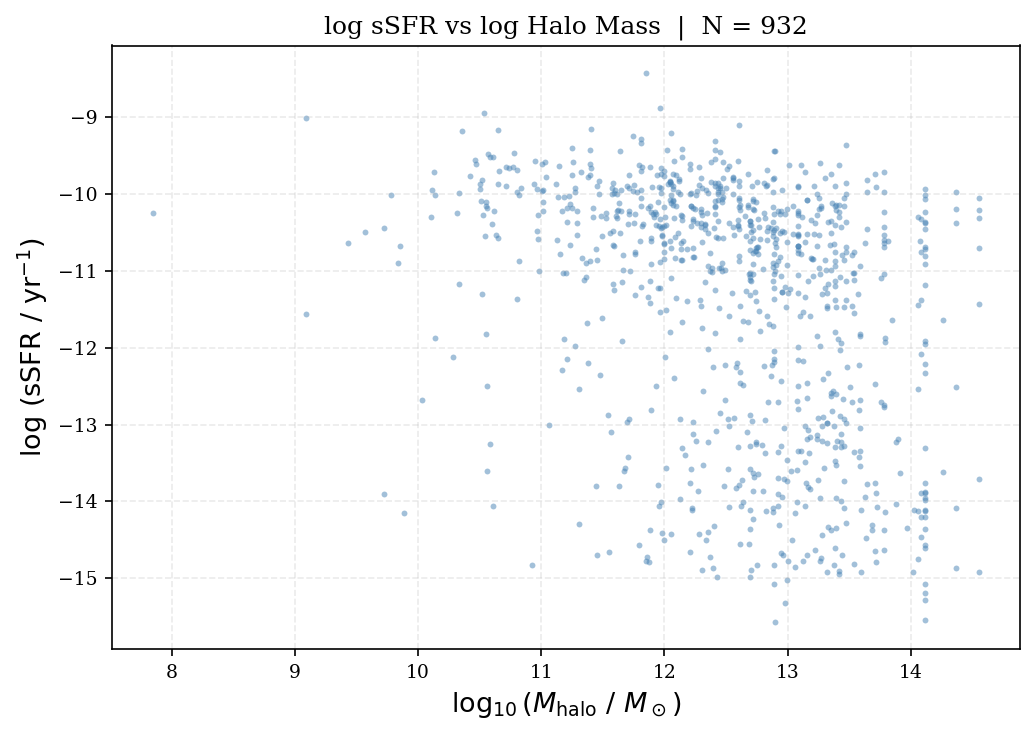

In [ ]:
""" sSFR vs Halo Mass"""

plot2 = df_check[["log_sSFR", "log_MassA_1"]].dropna()
print(f"Galaxies with both log_sSFR and log_MassA_1: {len(plot2):,}")

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    plot2["log_MassA_1"], plot2["log_sSFR"],
    s=8, alpha=0.5, linewidths=0, color="steelblue"
)

ax.set_xlabel(r"$\log_{10}(M_\mathrm{halo}\ /\ M_\odot)$", fontsize=13)
ax.set_ylabel(r"$\log\,(\mathrm{sSFR}\ /\ \mathrm{yr}^{-1})$", fontsize=13)
ax.set_title(f"log sSFR vs log Halo Mass  |  N = {len(plot2):,}", fontsize=12)

plt.tight_layout()
plt.show()

Galaxies with all three columns: 887


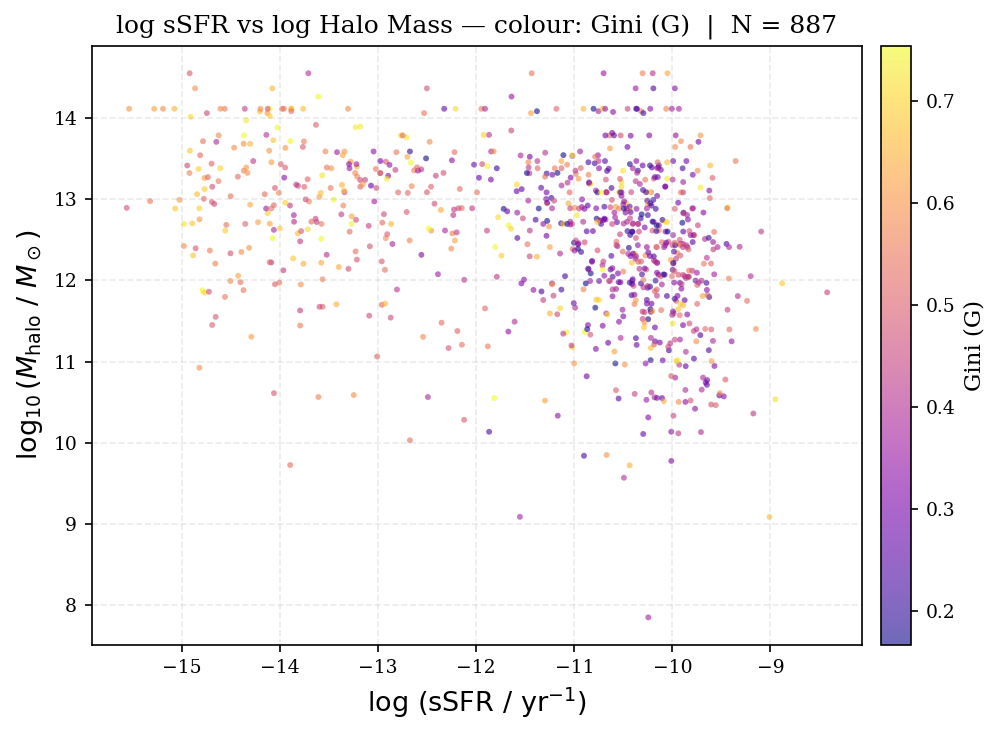

In [ ]:
""" sSFR vs Halo Mass (Coloured by Gini)"""

colour_col   = "G"                  # ← swap to "C", "A", or "S"
colour_label = "Gini (G)"          # ← update label to match

plot2 = df_check[["log_MassA_1", "log_sSFR", colour_col]].dropna()
print(f"Galaxies with all three columns: {len(plot2):,}")

fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    plot2["log_sSFR"], plot2["log_MassA_1"],
    c=plot2[colour_col],
    cmap="plasma",
    vmin=plot2[colour_col].quantile(0.02),
    vmax=plot2[colour_col].quantile(0.98),
    s=8, alpha=0.6, linewidths=0,
)

fig.colorbar(sc, ax=ax, label=colour_label, pad=0.02)

ax.set_xlabel(r"$\log\,(\mathrm{sSFR}\ /\ \mathrm{yr}^{-1})$", fontsize=13)
ax.set_ylabel(r"$\log_{10}(M_\mathrm{halo}\ /\ M_\odot)$", fontsize=13)
ax.set_title(f"log sSFR vs log Halo Mass — colour: {colour_label}  |  N = {len(plot2):,}", fontsize=12)

plt.tight_layout()
plt.show()

SAMI Galaxy Survey — Multi-Plot Analysis Scaffold

Loading: ../outputs/tables/master_results.csv
⚠ Correcting 1 malformed is_isolated value(s): ['Falsea']
  Raw catalogue  : 3,069 galaxies, 44 columns
  Spectral class ['pure_SF']: → 1,201
  Require all metrics (['G', 'C', 'A', 'S']): → 1,045
  Final sample   : 1,045 galaxies

Computing SFMS …
  SFMS (sample fit, N=1,041)
  log_SFR = 0.917 · log_Mstar + -9.376
  1σ scatter = 0.438 dex

Corner plot - Concenctration…


NameError: name 'SHOW_FIGURES' is not defined

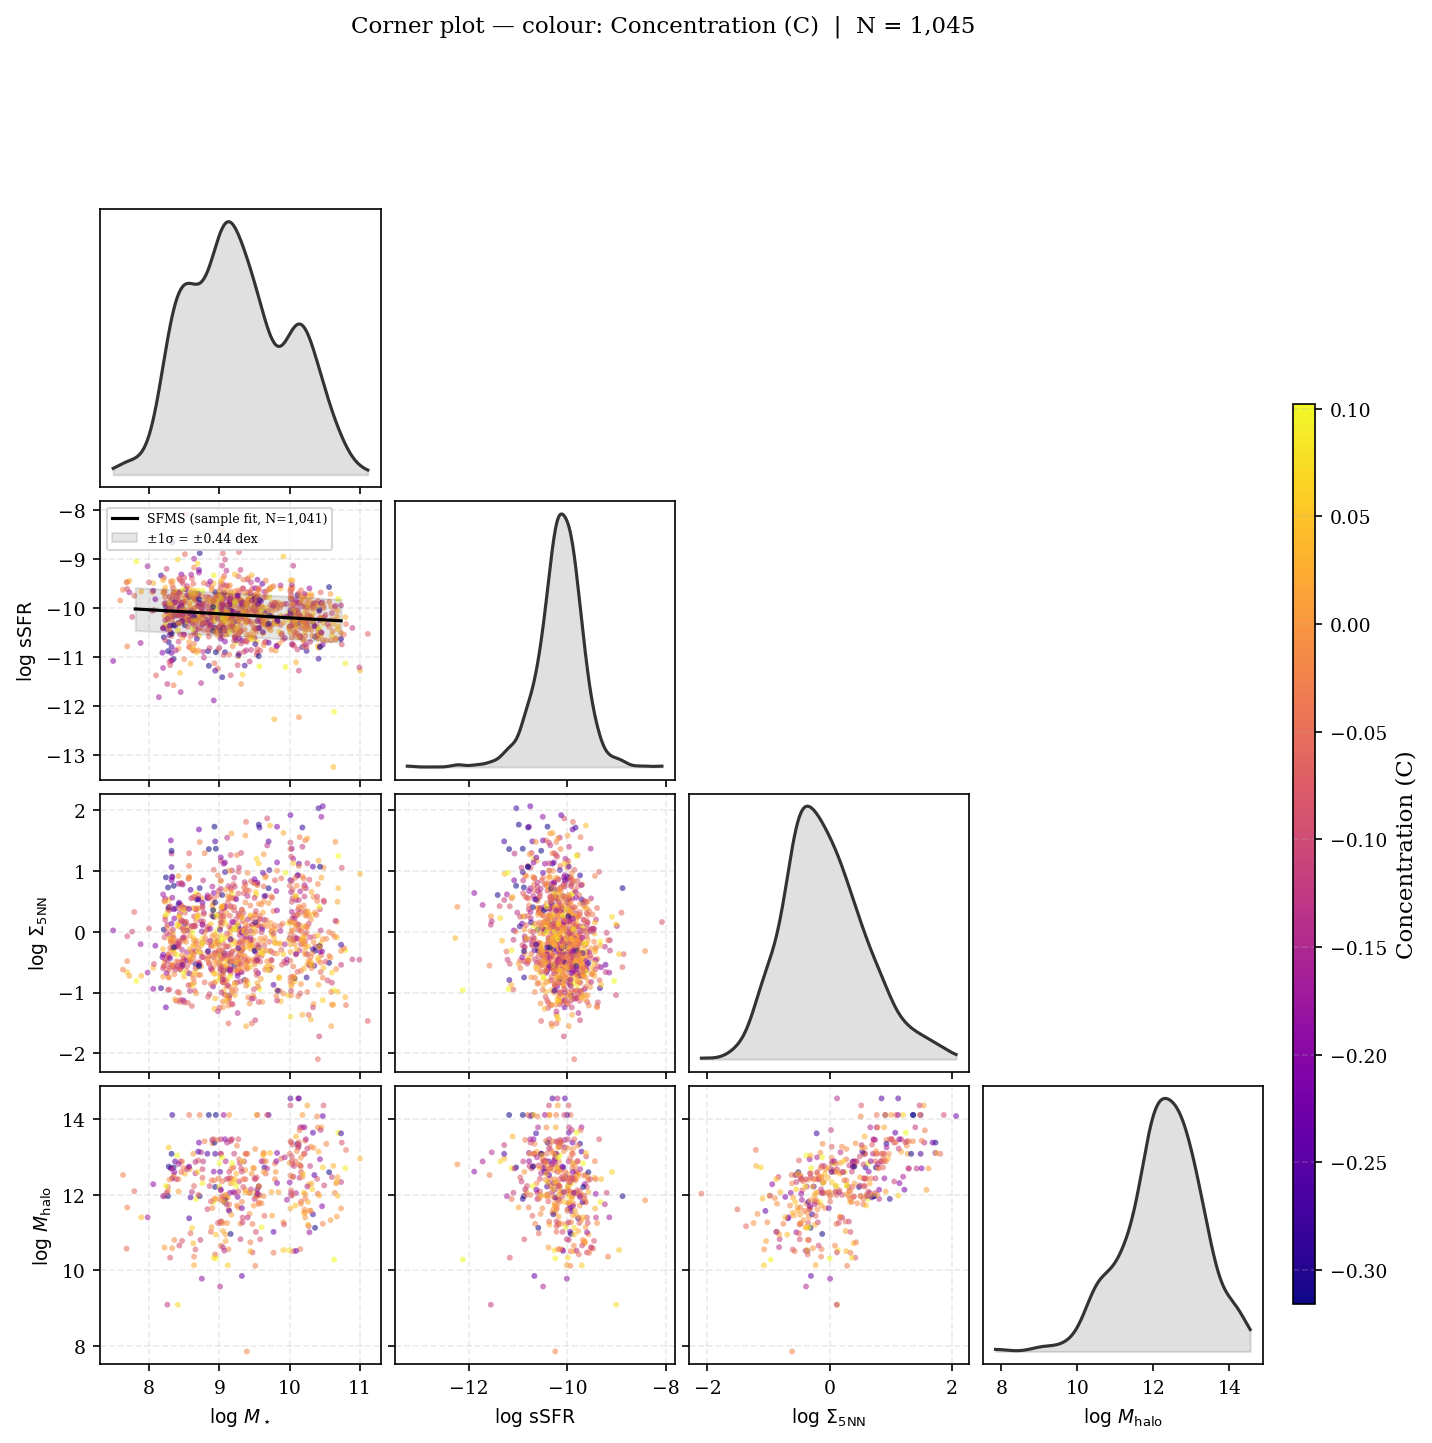

In [3]:
"""
================================================================================
SAMI GALAXY SURVEY — MULTI-PLOT ANALYSIS SCAFFOLD
================================================================================
Wired to: master_results.csv  (3069 galaxies, 42 columns)

Three plots, one config section (Section 3):

  PLOT 1 — Corner Plot
            Driver variables (log_Mstar, log_sSFR, log_5NN, log_MassA_1)
            with an SF metric colour-coded on every scatter cell.
            Run once per metric (G / C / A / S).

  SFMS    — Star-forming main sequence overlay drawn on any panel whose
            axes are log_Mstar (x) and log_SFR or log_sSFR (y).

================================================================================
DATA NOTES (master_results.csv)
  Internally used column names after cleaning:
      CATID, log_Mstar, log_SFR, log_sSFR,
      G, C, A, S,
      environment,          # "GAMA" | "Cluster"
      env3,                 # derived: "Isolated" | "Group/Field" | "Cluster"
      is_isolated,          # bool
      log_5NN,              # derived: log10(5NN)  — raw 5NN is not log-scaled
      log_MassA_1,          # BCG/halo mass proxy (1143 non-null)
      spectral_class        # "pure_SF" | "composite_SF"

  Sentinel / bad values cleaned on load:
      C  == -999   → NaN
      A  == inf    → NaN
================================================================================
STRUCTURE
  1. Imports & aesthetics
  2. Data loading & cleaning
  3. ══════════════════════════════════════════
     CONFIGURATION  ← only section to edit
  ══════════════════════════════════════════
  4. Data cuts (derived from config)
  5. SFMS helper
  6. Plot 1 — Corner plot
  7. Plot 2 — Heatmap grid
  8. Plot 3 — Violin plot
  9. Main execution
================================================================================
"""

# ── 1. IMPORTS & AESTHETICS ───────────────────────────────────────────────────

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import gaussian_kde

plt.rcParams.update({
    "figure.dpi":       150,
    "font.family":      "serif",
    "axes.labelsize":   11,
    "axes.titlesize":   11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "axes.grid":        True,
    "grid.alpha":       0.25,
    "grid.linestyle":   "--",
})


# ── 2. DATA LOADING & CLEANING ────────────────────────────────────────────────

def load_and_clean(filepath: str) -> pd.DataFrame:
    df = pd.read_csv(filepath)

    # ── Sentinel / bad value removal ──────────────────────────────────────
    df.loc[df["C"] == -999, "C"] = np.nan
    df.loc[np.isinf(df["A"]),  "A"] = np.nan

    # ── Fix is_isolated: CSV has a corrupted value 'Falsea' (CATID 7969) ──
    n_bad = (~df["is_isolated"].isin(["True", "False"])).sum()
    if n_bad:
        print(f"⚠ Correcting {n_bad} malformed is_isolated value(s): "
              f"{df.loc[~df['is_isolated'].isin(['True','False']), 'is_isolated'].unique().tolist()}")
    df["is_isolated"] = (
        df["is_isolated"].astype(str).str.strip()
        .replace({"Falsea": "False"})          # known data-entry typo
        .map({"True": True, "False": False})
    )
    df["is_isolated"] = df["is_isolated"].astype("boolean")

    # ── Derived columns ───────────────────────────────────────────────────
    df["log_5NN"] = np.log10(df["5NN"].clip(lower=1e-6))

    conditions = [
        (df["environment"] == "Cluster"),
        (df["environment"] == "GAMA") & (~df["is_isolated"]),
        (df["environment"] == "GAMA") & (df["is_isolated"]),
    ]
    choices = ["Cluster", "Group/Field", "Isolated"]
    df["env3"] = np.select(conditions, choices, default="Unknown")

    return df


# ── 3. CONFIGURATION ══════════════════════════════════════════════════════════
#
#   Edit ONLY this section between runs.
#   Everything below adapts automatically.
#
# ═════════════════════════════════════════════════════════════════════════════

# ── 3a. Data path ─────────────────────────────────────────────────────────────

DATA_PATH = "../outputs/tables/master_results.csv"


# ── 3b. Sample filter ─────────────────────────────────────────────────────────
#
#   SPECTRAL_CLASSES   "pure_SF" | "composite_SF" | both (None)             
#
#   REQUIRE_ALL_METRICS  If True, keep only galaxies that have G, C, A, and S.
#                        If False, each plot uses whatever is available per metric.
#
#   SSFR_CUT           Hard lower cut on log_sSFR (removes passive galaxies).
#                      Set to None to keep the full sample.
#                      Suggestion: -12.0  (removes the retired/passive tail)

SPECTRAL_CLASSES    = "pure_SF"           # ← None | "pure_SF" | "composite_SF"
REQUIRE_ALL_METRICS = True          # ← True | False
SSFR_CUT            = None          # ← float | None   e.g. -12.0


# ── 3c. Environment stratification ────────────────────────────────────────────
#
#   ENV_COL    Which environment column to use for grouping.
#              "environment"  →  2 bins: GAMA, Cluster
#              "env3"         →  3 bins: Isolated, Group/Field, Cluster
#              "is_isolated"  →  2 bins: True, False  (boolean cast to str)
#
#   ENV_ORDER  Display order of the bins (left → right in Plot 2, Plot 3).
#              Must match actual values in ENV_COL. Set to None to auto-detect.
#
#   ENV_COLORS One hex colour per bin in ENV_ORDER (used in Plot 3 violins).

ENV_COL    = "galclass"
ENV_ORDER  = [1, 2, 3, 4]   # ← None to auto
ENV_COLORS = ["#4C9BE8",  "#F5A623",     "#E84C4C", "#48811A"]


# ── 3d. SF metrics ────────────────────────────────────────────────────────────
#
#   These become the rows in Plot 2 and panels in Plot 3.
#   Comment out rows you don't want, or reorder freely.

METRICS = [
    {"col": "G", "label": "Gini (G)"},
    {"col": "C", "label": "Concentration (C)"},
    {"col": "A", "label": "Asymmetry (A)"},
    {"col": "S", "label": "Smoothness (S)"},
]


# ── 3e. Corner plot settings (Plot 1) ─────────────────────────────────────────
#
#   CORNER_DRIVERS   Variables on the corner plot axes.
#                    Must be numeric columns present after cleaning.
#
#   CORNER_METRIC    Which SF metric colours the scatter points.
#                    Must match a "col" value in METRICS.
#
#   CORNER_CMAP      Any matplotlib colourmap.

CORNER_DRIVERS = [
    {"col": "log_Mstar",   "label": r"$\log\,M_\star$"},
    {"col": "log_sSFR",    "label": r"$\log\,\mathrm{sSFR}$"},
    {"col": "log_5NN",     "label": r"$\log\,\Sigma_\mathrm{5NN}$"},
    {"col": "log_MassA_1", "label": r"$\log\,M_\mathrm{halo}$"},
]

CORNER_METRIC = "C"                  # ← "G" | "C" | "A" | "S"
CORNER_CMAP   = "plasma"


# ── 3g. Star-forming main sequence (SFMS) ─────────────────────────────────────
#
#   The SFMS is drawn on any panel whose x-axis is log_Mstar AND whose
#   y-axis is log_SFR or log_sSFR.
#
#   SFMS_SHOW      Master toggle. False suppresses SFMS on all plots.
#
#   SFMS_SOURCE    How to define the SFMS:
#       "fit"      — fit a line to the star-forming galaxies in your sample
#                    (log_sSFR > SFMS_FIT_SSFR_FLOOR).  Robust and self-consistent.
#       "renzini"  — Renzini & Peng (2015) parametrisation:
#                    log(SFR) = 0.76 * log(M★) − 7.64
#       "speagle"  — Speagle et al. (2014) at z = 0.08 (median z of SAMI):
#                    log(SFR) = (0.84 − 0.026*t) * log(M★) − (6.51 − 0.11*t)
#                    where t = age of universe at z=0.08 ≈ 12.4 Gyr
#       "manual"   — supply SFMS_SLOPE and SFMS_INTERCEPT directly
#                    (in log_SFR = slope * log_Mstar + intercept space)
#
#   SFMS_SCATTER   ±N-sigma shaded band around the SFMS line (0 = no band).
#
#   SFMS_FIT_SSFR_FLOOR   log_sSFR floor used when SFMS_SOURCE = "fit" to
#                          exclude passive galaxies from the fit.

SFMS_SHOW            = True
SFMS_SOURCE          = "fit"         # ← "fit" | "renzini" | "speagle" | "manual"
SFMS_SCATTER         = 1.0           # ← sigma bands (0 to suppress)
SFMS_FIT_SSFR_FLOOR  = -12.0        # ← used only when SFMS_SOURCE = "fit"
SFMS_SLOPE           = 0.675        # ← used only when SFMS_SOURCE = "manual"
SFMS_INTERCEPT       = -7.268       # ← used only when SFMS_SOURCE = "manual"


# ── 3h. Output ────────────────────────────────────────────────────────────────

# SAVE_FIGURES = True
# OUTPUT_DIR   = "."                   # ← folder for saved figures
# FIG_FORMAT   = "pdf"                 # ← "pdf" | "png" | "svg"
# SHOW_FIGURES = True

# ══ END OF CONFIGURATION ══════════════════════════════════════════════════════

# ── 4. DATA CUTS ──────────────────────────────────────────────────────────────

def prepare_data(filepath: str) -> pd.DataFrame:
    """Load, clean, and apply all sample filters from Section 3."""

    print(f"\nLoading: {filepath}")
    df = load_and_clean(filepath)
    print(f"  Raw catalogue  : {len(df):,} galaxies, {df.shape[1]} columns")

    # Spectral class filter
    if SPECTRAL_CLASSES is not None:
        targets = ([SPECTRAL_CLASSES]
                   if isinstance(SPECTRAL_CLASSES, str)
                   else list(SPECTRAL_CLASSES))
        df = df[df["spectral_class"].isin(targets)]
        print(f"  Spectral class {targets}: → {len(df):,}")

    # sSFR hard cut
    if SSFR_CUT is not None and "log_sSFR" in df.columns:
        df = df[df["log_sSFR"].isna() | (df["log_sSFR"] >= SSFR_CUT)]
        print(f"  log_sSFR ≥ {SSFR_CUT}: → {len(df):,}")

    # Require all four metrics simultaneously
    if REQUIRE_ALL_METRICS:
        metric_cols = [m["col"] for m in METRICS]
        df = df.dropna(subset=metric_cols)
        print(f"  Require all metrics ({metric_cols}): → {len(df):,}")

    # Surface Density 
    if "SurfaceDensityFlag" in df.columns:
        df = df[df["SurfaceDensityFlag"] <= 1]

    # Warn if ENV_COL has unexpected NaNs
    n_env_null = df[ENV_COL].isna().sum() if ENV_COL in df.columns else 0
    if n_env_null > 0:
        print(f"  ⚠  {n_env_null} galaxies have NaN in '{ENV_COL}' — excluded from env-split plots")

    print(f"  Final sample   : {len(df):,} galaxies\n")
    return df


def get_env_bins(df: pd.DataFrame) -> list:
    """Return the ordered list of environment bin labels to use."""
    if ENV_ORDER is not None:
        return ENV_ORDER
    return sorted(df[ENV_COL].dropna().unique().tolist())


# ── 5. SFMS HELPER ────────────────────────────────────────────────────────────

def compute_sfms(df: pd.DataFrame) -> dict:
    """
    Return a dict with keys:
        slope, intercept   — log_SFR = slope * log_Mstar + intercept
        sigma              — 1-sigma scatter of SF galaxies around the line
        label              — legend string
    Uses SFMS_SOURCE to select the parametrisation.
    """
    if SFMS_SOURCE == "renzini":
        slope, intercept = 0.76, -7.64
        label = "SFMS (Renzini & Peng 2015)"

    elif SFMS_SOURCE == "speagle":
        t = 12.4          # Gyr — age of universe at z ≈ 0.08
        slope     = 0.84 - 0.026 * t
        intercept = -(6.51 - 0.11 * t)
        label = "SFMS (Speagle+2014, z=0.08)"

    elif SFMS_SOURCE == "manual":
        slope, intercept = SFMS_SLOPE, SFMS_INTERCEPT
        label = f"SFMS (manual: {slope:.2f}·M★ + {intercept:.2f})"

    else:  # "fit" — default
        sf = df[
            df["log_SFR"].notna() &
            df["log_Mstar"].notna() &
            (df["log_sSFR"] >= SFMS_FIT_SSFR_FLOOR)
        ]
        if len(sf) < 20:
            print("  ⚠  Too few SF galaxies for SFMS fit — falling back to Renzini & Peng")
            return compute_sfms_override("renzini", df)
        coeffs = np.polyfit(sf["log_Mstar"], sf["log_SFR"], 1)
        slope, intercept = coeffs[0], coeffs[1]
        label = f"SFMS (sample fit, N={len(sf):,})"

    # Compute scatter around the line using SF galaxies
    sf_all = df[df["log_SFR"].notna() & df["log_Mstar"].notna()]
    if SFMS_SOURCE in ("fit",):
        sf_all = sf_all[sf_all["log_sSFR"] >= SFMS_FIT_SSFR_FLOOR]
    residuals = sf_all["log_SFR"] - (slope * sf_all["log_Mstar"] + intercept)
    sigma = residuals.std() if len(residuals) > 5 else 0.3

    return {"slope": slope, "intercept": intercept, "sigma": sigma, "label": label}


def compute_sfms_override(source, df):
    """Internal fallback — temporarily overrides SFMS_SOURCE."""
    global SFMS_SOURCE
    orig = SFMS_SOURCE
    SFMS_SOURCE = source
    result = compute_sfms(df)
    SFMS_SOURCE = orig
    return result


def draw_sfms(ax, sfms: dict, x_col: str, y_col: str,
              mass_range: tuple = (7.0, 12.5)) -> None:
    """
    Draw the SFMS line (and optional scatter band) onto ax.
    Handles both log_SFR and log_sSFR y-axes automatically.
    Only draws if x_col == "log_Mstar" and y_col is SFR-related.
    """
    if not SFMS_SHOW:
        return
    if x_col != "log_Mstar":
        return
    if y_col not in ("log_SFR", "log_sSFR"):
        return

    xline = np.linspace(mass_range[0], mass_range[1], 200)
    yline_sfr = sfms["slope"] * xline + sfms["intercept"]

    if y_col == "log_sSFR":
        yline = yline_sfr - xline        # log_sSFR = log_SFR − log_Mstar
    else:
        yline = yline_sfr

    ax.plot(xline, yline, color="black", lw=1.5, ls="-",
            label=sfms["label"], zorder=6)

    if SFMS_SCATTER > 0:
        sigma = sfms["sigma"]
        ax.fill_between(
            xline,
            yline - SFMS_SCATTER * sigma,
            yline + SFMS_SCATTER * sigma,
            color="black", alpha=0.10, zorder=5,
            label=f"±{SFMS_SCATTER:.0f}σ = ±{sigma:.2f} dex",
        )


# ── 6. PLOT 1 — CORNER PLOT ───────────────────────────────────────────────────

def _pct_norm(series: pd.Series, cmap_name: str):
    vmin = series.quantile(0.02)
    vmax = series.quantile(0.98)
    return Normalize(vmin=vmin, vmax=vmax), plt.get_cmap(cmap_name)


def plot_corner(df: pd.DataFrame, sfms: dict) -> plt.Figure:
    """
    Plot 1 — Corner plot.
    Lower triangle : scatter coloured by CORNER_METRIC.
    Diagonal       : KDE of each driver variable.
    Upper triangle : empty.
    SFMS drawn on any cell with log_Mstar (x) vs log_SFR / log_sSFR (y).
    """
    drivers = CORNER_DRIVERS
    n       = len(drivers)
    metric  = CORNER_METRIC
    metric_label = next((m["label"] for m in METRICS if m["col"] == metric), metric)

    # Work only with rows that have the metric available
    plot_df = df.dropna(subset=[metric])
    norm, cmap = _pct_norm(plot_df[metric], CORNER_CMAP)

    fig, axes = plt.subplots(n, n, figsize=(10, 10), sharex="col")
    fig.subplots_adjust(hspace=0.05, wspace=0.05)

    for row in range(n):
        for col in range(n):
            ax = axes[row, col]

            # Upper triangle — hide
            if col > row:
                ax.set_visible(False)
                continue

            x_col = drivers[col]["col"]
            y_col = drivers[row]["col"]

            # Diagonal — KDE
            if col == row:
                vals = plot_df[x_col].dropna().values
                if len(vals) > 5:
                    kde = gaussian_kde(vals, bw_method="scott")
                    xs  = np.linspace(vals.min(), vals.max(), 300)
                    ax.plot(xs, kde(xs), color="#333333", lw=1.5)
                    ax.fill_between(xs, kde(xs), alpha=0.15, color="#333333")
                ax.set_yticks([])
                ax.grid(False)

            # Lower triangle — scatter
            else:
                sub = plot_df[[x_col, y_col, metric]].dropna()
                ax.scatter(
                    sub[x_col], sub[y_col],
                    c=sub[metric], cmap=cmap, norm=norm,
                    s=8, alpha=0.55, linewidths=0, rasterized=True,
                )
                draw_sfms(ax, sfms, x_col, y_col,
                          mass_range=(df["log_Mstar"].quantile(0.01),
                                      df["log_Mstar"].quantile(0.99)))
                # Legend only on the first cell that has the SFMS
                if x_col == "log_Mstar" and y_col in ("log_SFR", "log_sSFR"):
                    ax.legend(fontsize=6, loc="upper left")

            # Axis labels — outer edges only
            if row == n - 1:
                ax.set_xlabel(drivers[col]["label"], fontsize=9)
            else:
                ax.tick_params(labelbottom=False)

            if col == 0 and row != 0:
                ax.set_ylabel(drivers[row]["label"], fontsize=9)
            else:
                ax.tick_params(labelleft=False)

    # Shared colourbar
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.6])
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap),
                 cax=cbar_ax, label=metric_label)

    fig.suptitle(
        f"Corner plot — colour: {metric_label}  |  N = {len(plot_df):,}",
        y=1.01, fontsize=11,
    )
    return fig


# ── 9. MAIN EXECUTION ─────────────────────────────────────────────────────────

def main():
    print("=" * 64)
    print("SAMI Galaxy Survey — Multi-Plot Analysis Scaffold")
    print("=" * 64)

    df = prepare_data(DATA_PATH)

    # Compute SFMS once — shared across all plots
    print("Computing SFMS …")
    sfms = compute_sfms(df)
    print(f"  {sfms['label']}")
    print(f"  log_SFR = {sfms['slope']:.3f} · log_Mstar + {sfms['intercept']:.3f}")
    print(f"  1σ scatter = {sfms['sigma']:.3f} dex\n")

    # ── Corner plot ───────────────────────────────────────────────
    print("Corner plot - Concenctration…")
    fig1 = plot_corner(df, sfms)
    if SHOW_FIGURES:
        plt.show()


if __name__ == "__main__":
    main()

SAMI Galaxy Survey — Corner Plot Scaffold

Loading: ../outputs/tables/master_results.csv
  Raw catalogue  : 3,069 galaxies
  Final sample   : 3,069 galaxies

Fitting SFMS (Lee+2015 ridge line)
  Lee+2015 fit: S0=3261.086, a1=241.567, Mt=9.889
  1σ scatter = 0.398 dex

Generating corner plot …


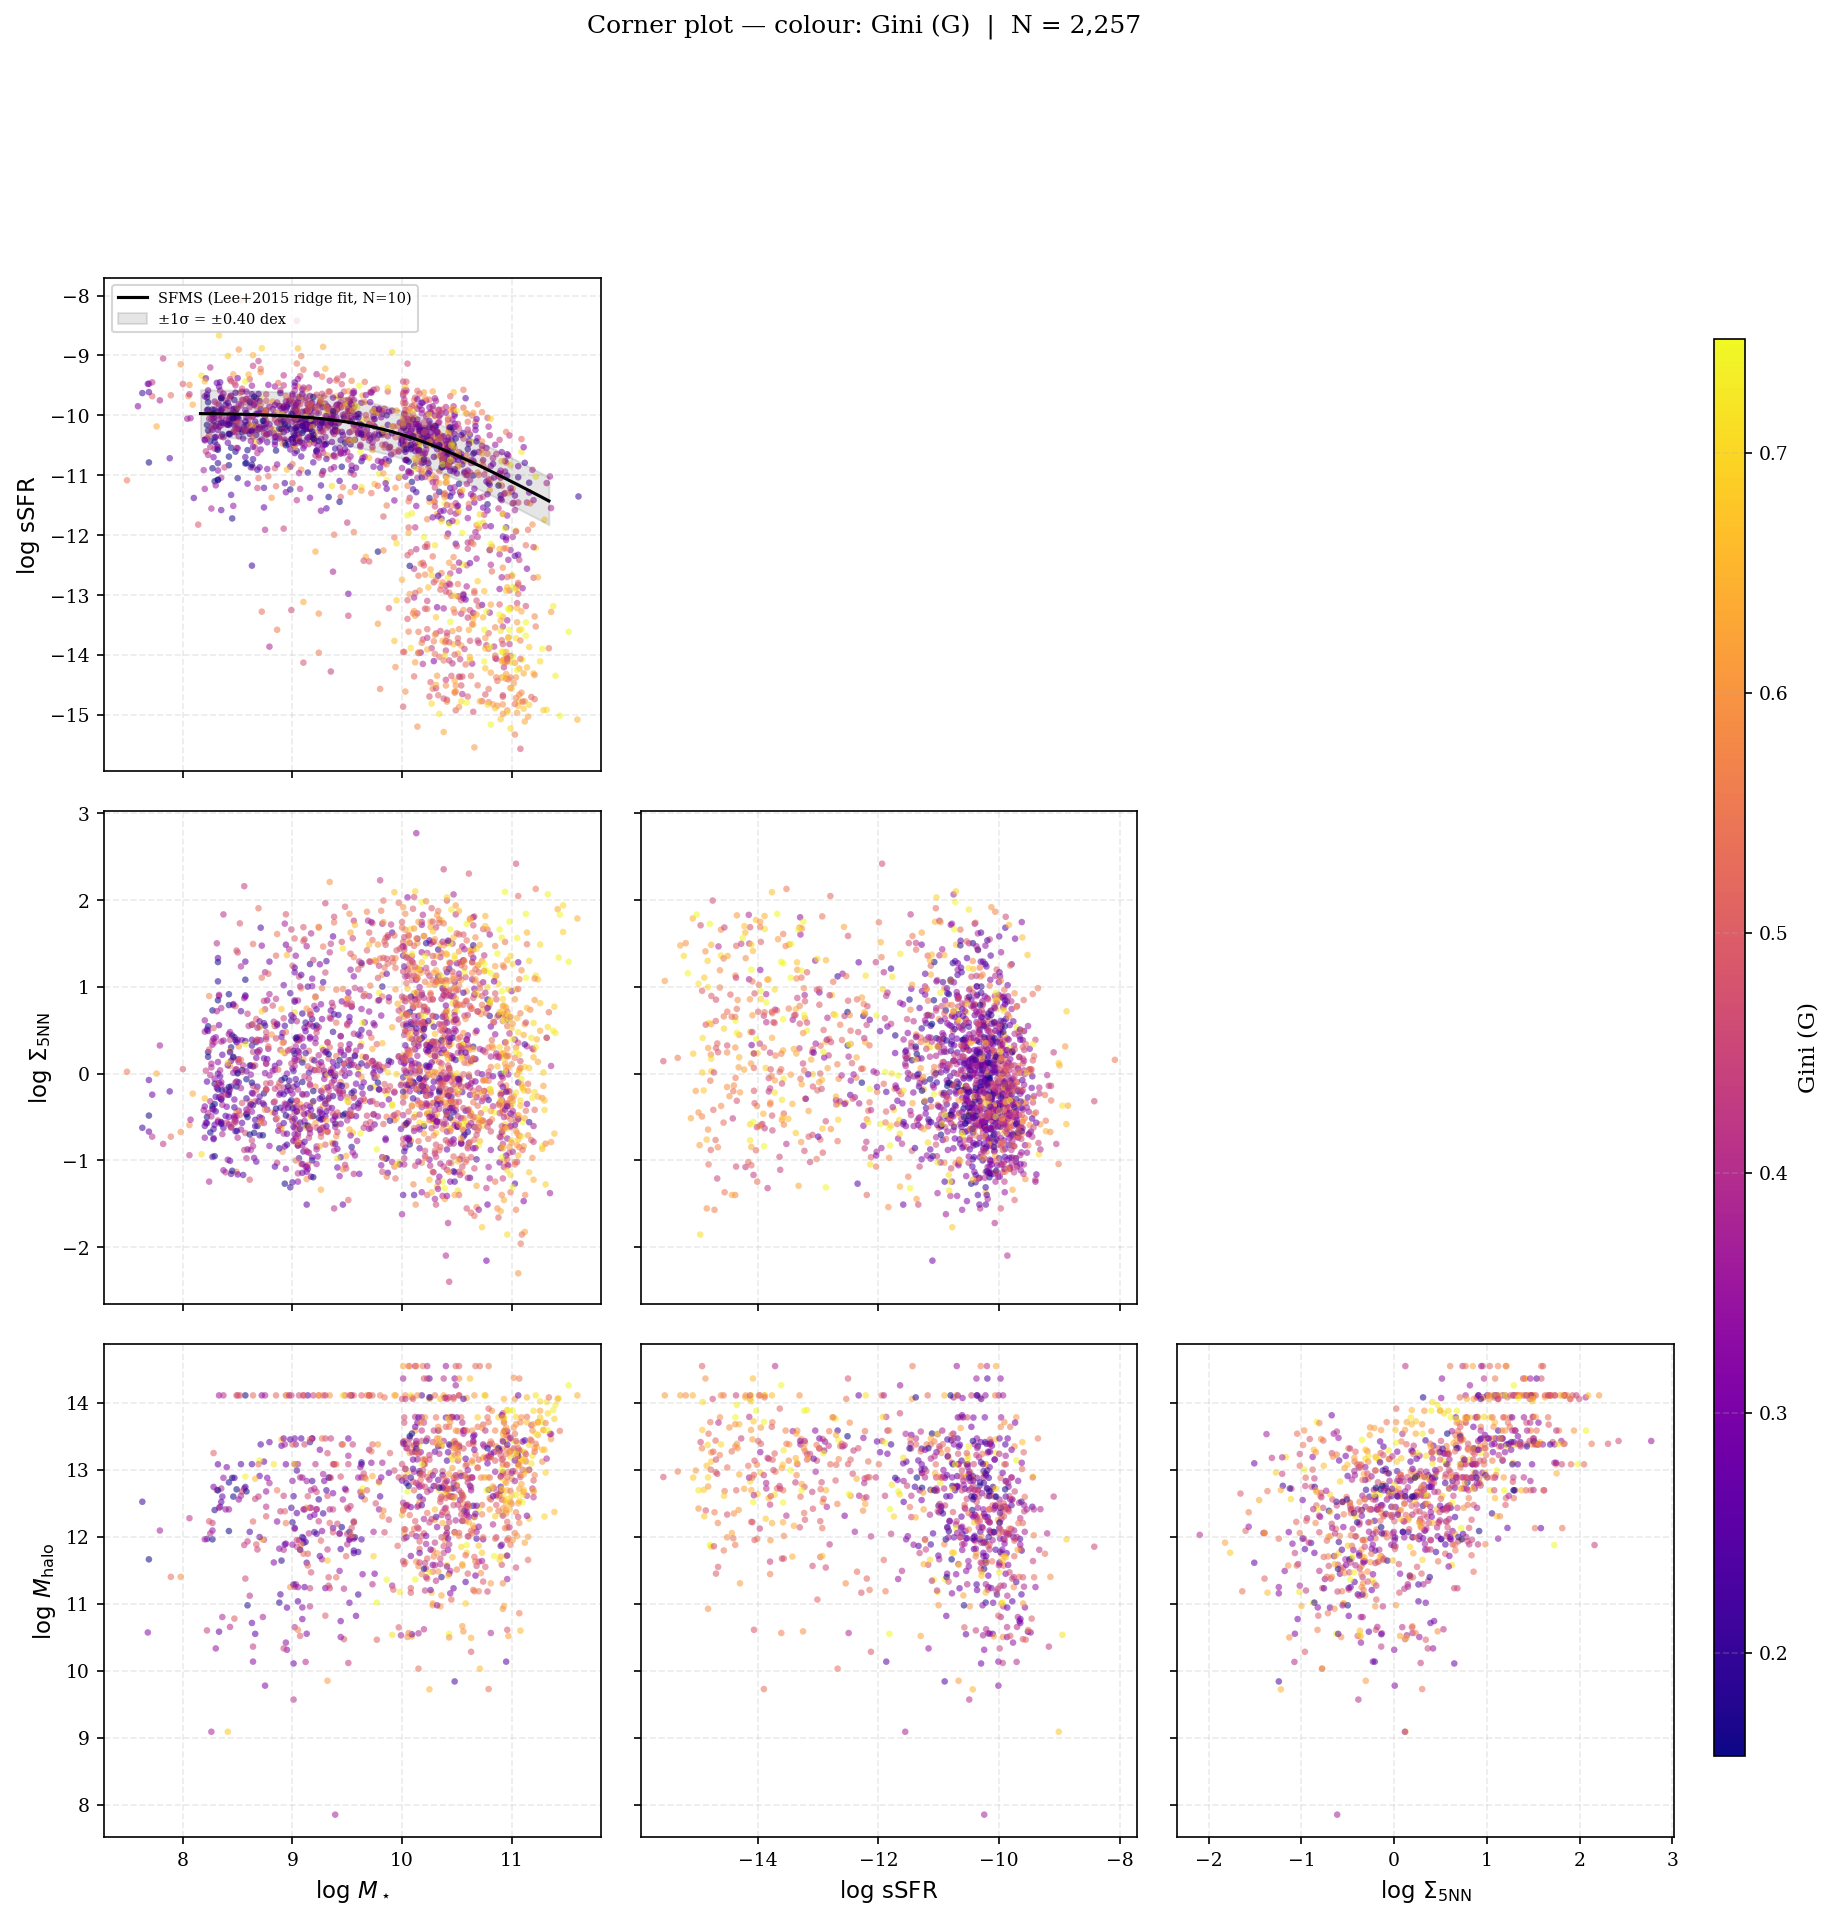

In [ ]:
"""
================================================================================
SAMI GALAXY SURVEY — CORNER PLOT ANALYSIS SCAFFOLD
================================================================================
Wired to: master_results.csv  (3069 galaxies, 42 columns)
SFMS:     src/sfms.py  (Lee+2015 turnover form, ridge-line fit)

PLOT 1 — Corner Plot
          Driver variables (log_Mstar, log_sSFR, log_5NN, log_MassA_1)
          with an SF metric colour-coded on every scatter cell.
          SFMS drawn on any panel with log_Mstar (x) vs log_SFR/log_sSFR (y).

================================================================================
STRUCTURE
  1. Imports
  2. Data loading & cleaning
  3. ══════════════════════════════════════════
     CONFIGURATION  ← only section to edit
  ══════════════════════════════════════════
  4. Data preparation
  5. Corner plot
  6. Main execution
================================================================================
"""

# ── 1. IMPORTS ────────────────────────────────────────────────────────────────

import warnings
warnings.filterwarnings("ignore")

import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import gaussian_kde

# Add src/ to path so sfms.py can be imported from master/src/sfms.py
sys.path.append(os.path.abspath("../../src"))
from sfms import lee2015_sfms, fit_ridge_line, compute_delta_ms

plt.rcParams.update({
    "figure.dpi":       150,
    "font.family":      "serif",
    "axes.labelsize":   11,
    "axes.titlesize":   11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "axes.grid":        True,
    "grid.alpha":       0.25,
    "grid.linestyle":   "--",
})


# ── 2. DATA LOADING & CLEANING ────────────────────────────────────────────────

def load_and_clean(filepath: str) -> pd.DataFrame:
    df = pd.read_csv(filepath)

    # Sentinel / bad value removal
    df.loc[df["C"] == -999, "C"] = np.nan
    df.loc[np.isinf(df["A"]),  "A"] = np.nan

    # log-scale 5NN (raw values are already surface density in Mpc⁻²)
    df["log_5NN"] = np.log10(df["5NN"].clip(lower=1e-6))

    # Three-way environment label
    conditions = [
        (df["environment"] == "Cluster"),
        (df["environment"] == "GAMA") & (~df["is_isolated"]),
        (df["environment"] == "GAMA") & (df["is_isolated"]),
    ]
    choices = ["Cluster", "Group/Field", "Isolated"]
    df["env3"] = np.select(conditions, choices, default="Unknown")

    return df


# ── 3. CONFIGURATION ══════════════════════════════════════════════════════════
#
#   Edit ONLY this section between runs.
#
# ═════════════════════════════════════════════════════════════════════════════

# ── 3a. Data path ─────────────────────────────────────────────────────────────

DATA_PATH = "../outputs/tables/master_results.csv"


# ── 3b. Sample filter ─────────────────────────────────────────────────────────
#
#   SPECTRAL_CLASSES   None | "pure_SF" | "composite_SF"
#   SSFR_CUT           Hard lower cut on log_sSFR. None to keep all.

SPECTRAL_CLASSES = None
SSFR_CUT         = None              # ← e.g. -12.0 to remove passive galaxies


# ── 3c. Corner plot drivers ───────────────────────────────────────────────────
#
#   Variables shown on the corner plot axes.
#   Any numeric column from the cleaned dataframe is valid.

CORNER_DRIVERS = [
    {"col": "log_Mstar",   "label": r"$\log\,M_\star$"},
    {"col": "log_sSFR",    "label": r"$\log\,\mathrm{sSFR}$"},
    {"col": "log_5NN",     "label": r"$\log\,\Sigma_\mathrm{5NN}$"},
    {"col": "log_MassA_1", "label": r"$\log\,M_\mathrm{halo}$"},
]


# ── 3d. Colour metric ─────────────────────────────────────────────────────────
#
#   Which SF metric colours the scatter points.
#   Options: "G" | "C" | "A" | "S"

CORNER_METRIC = "G"                  # ← change to "C", "A", or "S"
CORNER_CMAP   = "plasma"


# ── 3e. SFMS settings ─────────────────────────────────────────────────────────
#
#   SFMS_SHOW          Master toggle.
#   SFMS_SCATTER       Draw ±N-sigma band. 0 to suppress.
#   SFMS_MASS_RANGE    Mass range used for fitting the ridge line.
#   SFMS_SFR_FLOOR     log(SFR) floor passed to fit_ridge_line() to exclude
#                      the quenched tail from the fit. -1.0 per Tuntipong+2024.

SFMS_SHOW        = True
SFMS_SCATTER     = 1.0               # ← sigma bands (0 to suppress)
SFMS_MASS_RANGE  = (9.0, 11.0)      # ← passed to fit_ridge_line()
SFMS_SFR_FLOOR   = -1.0             # ← log(SFR) floor for ridge-line fit

# ══ END OF CONFIGURATION ══════════════════════════════════════════════════════


# ── 4. DATA PREPARATION ───────────────────────────────────────────────────────

def prepare_data(filepath: str) -> pd.DataFrame:
    print(f"\nLoading: {filepath}")
    df = load_and_clean(filepath)
    print(f"  Raw catalogue  : {len(df):,} galaxies")

    if SPECTRAL_CLASSES is not None:
        targets = ([SPECTRAL_CLASSES] if isinstance(SPECTRAL_CLASSES, str)
                   else list(SPECTRAL_CLASSES))
        df = df[df["spectral_class"].isin(targets)]
        print(f"  Spectral class {targets}: → {len(df):,}")

    if SSFR_CUT is not None:
        df = df[df["log_sSFR"].isna() | (df["log_sSFR"] >= SSFR_CUT)]
        print(f"  log_sSFR ≥ {SSFR_CUT}: → {len(df):,}")

    print(f"  Final sample   : {len(df):,} galaxies\n")
    return df


# ── 5. SFMS ───────────────────────────────────────────────────────────────────

def compute_sfms(df: pd.DataFrame) -> dict:
    """
    Fit the Lee+2015 SFMS to the ridge line of the star-forming population.
    Returns params, scatter sigma, and a label string for the legend.
    """
    sf = df[df["log_SFR"].notna() & df["log_Mstar"].notna()].copy()

    sfms_params, ridge_mass, ridge_sfr = fit_ridge_line(
        sf["log_Mstar"].values,
        sf["log_SFR"].values,
        mass_range  = SFMS_MASS_RANGE,
        sfr_floor   = SFMS_SFR_FLOOR,
    )

    S0, a1, Mt = sfms_params
    print(f"  Lee+2015 fit: S0={S0:.3f}, a1={a1:.3f}, Mt={Mt:.3f}")

    # Scatter: std of residuals for galaxies on/above the SFR floor
    sf_fit = sf[sf["log_SFR"] >= SFMS_SFR_FLOOR]
    residuals = sf_fit["log_SFR"].values - lee2015_sfms(
        sf_fit["log_Mstar"].values, S0, a1, Mt
    )
    sigma = residuals.std()
    print(f"  1σ scatter = {sigma:.3f} dex\n")

    return {
        "params": sfms_params,
        "sigma":  sigma,
        "label":  f"SFMS (Lee+2015 ridge fit, N={len(ridge_mass)})",
    }


def draw_sfms(ax, sfms: dict, x_col: str, y_col: str,
              mass_range: tuple = (7.0, 12.5)) -> None:
    """
    Draw the SFMS line and optional scatter band onto ax.
    Only draws when x_col = log_Mstar and y_col is SFR-related.
    Handles both log_SFR and log_sSFR y-axes.
    """
    if not SFMS_SHOW:
        return
    if x_col != "log_Mstar" or y_col not in ("log_SFR", "log_sSFR"):
        return

    S0, a1, Mt = sfms["params"]
    xline       = np.linspace(mass_range[0], mass_range[1], 200)
    yline_sfr   = lee2015_sfms(xline, S0, a1, Mt)

    yline = yline_sfr - xline if y_col == "log_sSFR" else yline_sfr

    ax.plot(xline, yline, color="black", lw=1.5, ls="-",
            label=sfms["label"], zorder=6)

    if SFMS_SCATTER > 0:
        sigma = sfms["sigma"]
        ax.fill_between(
            xline,
            yline - SFMS_SCATTER * sigma,
            yline + SFMS_SCATTER * sigma,
            color="black", alpha=0.10, zorder=5,
            label=f"±{SFMS_SCATTER:.0f}σ = ±{sigma:.2f} dex",
        )


# ── 6. CORNER PLOT ────────────────────────────────────────────────────────────

def plot_corner(df: pd.DataFrame, sfms: dict) -> plt.Figure:
    drivers      = CORNER_DRIVERS
    n            = len(drivers)
    metric       = CORNER_METRIC
    metric_label = {"G": "Gini (G)", "C": "Concentration (C)",
                    "A": "Asymmetry (A)", "S": "Smoothness (S)"}.get(metric, metric)

    plot_df = df.dropna(subset=[metric])
    vmin    = plot_df[metric].quantile(0.02)
    vmax    = plot_df[metric].quantile(0.98)
    norm    = Normalize(vmin=vmin, vmax=vmax)
    cmap    = plt.get_cmap(CORNER_CMAP)

    # Build only the lower triangle — (n-1) rows × (n-1) cols
    n_panels = n - 1
    fig, axes = plt.subplots(
        n_panels, n_panels,
        figsize=(4.5 * n_panels, 4.5 * n_panels),
        sharex="col", sharey="row",
    )
    fig.subplots_adjust(hspace=0.08, wspace=0.08)

    for row in range(n_panels):
        for col in range(n_panels):
            ax    = axes[row, col]
            # row 0 = drivers[1] on y, col 0 = drivers[0] on x
            x_col = drivers[col]["col"]
            y_col = drivers[row + 1]["col"]

            # Hide cells above the diagonal of the lower triangle
            if col > row:
                ax.set_visible(False)
                continue

            sub = plot_df[[x_col, y_col, metric]].dropna()
            ax.scatter(
                sub[x_col], sub[y_col],
                c=sub[metric], cmap=cmap, norm=norm,
                s=10, alpha=0.55, linewidths=0, rasterized=True,
            )

            draw_sfms(ax, sfms, x_col, y_col,
                      mass_range=(df["log_Mstar"].quantile(0.01),
                                  df["log_Mstar"].quantile(0.99)))

            if x_col == "log_Mstar" and y_col in ("log_SFR", "log_sSFR"):
                ax.legend(fontsize=7, loc="upper left")

            # x labels on bottom row only
            if row == n_panels - 1:
                ax.set_xlabel(drivers[col]["label"], fontsize=11)
            else:
                ax.tick_params(labelbottom=False)

            # y labels on left column only
            if col == 0:
                ax.set_ylabel(drivers[row + 1]["label"], fontsize=11)
            else:
                ax.tick_params(labelleft=False)

    # Colourbar
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap),
                 cax=cbar_ax, label=metric_label)

    fig.suptitle(
        f"Corner plot — colour: {metric_label}  |  N = {len(plot_df):,}",
        y=1.01, fontsize=12,
    )
    return fig


# ── 7. MAIN ───────────────────────────────────────────────────────────────────

def main():
    print("=" * 64)
    print("SAMI Galaxy Survey — Corner Plot Scaffold")
    print("=" * 64)

    df = prepare_data(DATA_PATH)

    print("Fitting SFMS (Lee+2015 ridge line)")
    sfms = compute_sfms(df)

    print("Generating corner plot …")
    fig = plot_corner(df, sfms)
    plt.show()

if __name__ == "__main__":
    main()